# Índice por regressão ordinal — base mock do hackathon
Este notebook lê a execução congelada. Para refazer o experimento completo, execute `executar.py`. Não reotimiza a partir do teste.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
p = Path.cwd()
display(Markdown((p/'RELATORIO_RESULTADOS.md').read_text()))

# Resultado do índice por regressão — base mock fornecida

Executado em 28/10/2026. **Modelo treinado de fato no desenvolvimento fornecido: 2978 estabelecimentos. Teste externo: 144 estabelecimentos de 120 empresas.** Não é a simulação matemática anterior.

## Resultado principal

Concordância com os planos de referência construídos: **80.56% (116/144)**. Macro-F1: 0.7856; acurácia balanceada: 77.59%. Intervalo bootstrap por empresa para concordância: 73.6%–86.8%. Referência simples de classe mais frequente: 45.83%. A regra geradora teria 100% por definição, sem comprovar adequação comercial.

A seleção interna escolheu **patrimonio_emprego**, regularização 0.1. Quatro conjuntos de variáveis e três penalidades foram comparados em três dobras por empresa. A concordância interna média foi 84.15%. O teste externo não foi usado para escolher o modelo.

## Fórmula aprendida

z = 2.916990 × funcionários_padronizados + 1.395199 × estoque_padronizado + 1.012302 × bens_padronizados.

score = 1/(1+exp(-z)). Cada variável é padronizada depois de log(1+valor); use as médias e desvios em `formula_parametros.json`. Não multiplicar os pesos diretamente pelos valores brutos em reais. A fórmula independente foi conferida contra todos os scores do teste.

| termo | peso_beta | ic_bootstrap_2_5 | ic_bootstrap_97_5 | sinal_estavel_condicional | media_abs_contribuicao_treino |
| --- | --- | --- | --- | --- | --- |
| num__funcionarios_estimados_empresa | 2.91699 | 2.647883 | 3.23925 | True | 2.561075 |
| num__estoque_medio_estimado | 1.395199 | 1.226972 | 1.533605 | True | 1.125937 |
| num__valor_bens_ponderado_estabelecimento | 1.012302 | 0.756573 | 1.227932 | True | 0.831348 |

Os três sinais ficaram positivos nas reamostragens. Isso é estabilidade condicional à referência proposta; **não é prova de significância estatística independente ou causalidade**. Os pesos são estimados, mas favorecem as variáveis que a política escolheu para criar os rótulos.

## Faixas aprendidas

| Score sem arredondamento | Indicação |
|---|---|
| 0 ≤ S < 0.210735828 | Essencial |
| 0.210735828 ≤ S < 0.984372567 | Prático |
| 0.984372567 ≤ S ≤ 1 | Total |

Os limites vêm dos dois limiares estimados da regressão, transformados pela função logística. A indicação usa a mediana ordinal; pode diferir da maior probabilidade de classe. Não arredondar o score antes de enquadrar. O intervalo do Total é estreito porque esta escala concentra scores altos perto de 1; não representa pouca frequência de clientes Total. Precisão decimal não significa certeza comercial.

## O que funcionou e o que não funcionou

- Empregados, estoque e bens foram suficientes para a melhor log-loss ordinal interna. Faturamento, contexto, área e termos de endereço não melhoraram o critério de seleção nesta comparação; isso não prova que sejam irrelevantes fora desta política.
- No teste: Essencial 64/66, Prático 24/43, Total 28/35. Prático foi a classe mais difícil: 16 casos desceram para Essencial e 3 subiram para Total. Houve 28 divergências no total, todas entre classes vizinhas.
- O comparador de regressão multinomial obteve log-loss interna 0,2133 e concordância 91,57%, contra 0,3759 e 84,15% da ordinal. **A ordinal não foi o melhor classificador comparado.** Sua restrição de um único eixo e pesos comuns custa desempenho nesta política. Mantivemos a ordinal como versão experimental por entregar o índice unidimensional solicitado; não a apresentamos como vencedora geral.
- Alterar a política muda aproximadamente 21%–23% das indicações internas. Portanto as recomendações dependem materialmente das hipóteses. Nenhum dos cenários foi escolhido pelo resultado do teste.
- As probabilidades não foram calibradas para vendas reais; não representam chance de contratação. A avaliação mede reprodução de uma política construída.

## Sensibilidade

| cenario | mudanca_recomendacao_oof | variacao_media_score_oof | corte1 | corte2 |
| --- | --- | --- | --- | --- |
| central | 0.0 | 0.0 | 0.210736 | 0.984373 |
| mais_abrangente | 0.210208 | 0.012816 | 0.030794 | 0.930508 |
| mais_restritivo | 0.231363 | 0.010719 | 0.657662 | 0.996341 |

Os pesos por cenário e os intervalos bootstrap estão nos arquivos anexos. O score médio muda pouco, mas os cortes mudam bastante; nunca misturar score de uma versão com cortes de outra.

## Exemplos, incluindo erros

Primeiro caso disponível de cada referência e primeiro erro de cada classe, sem escolher apenas acertos:

| empresa_id | imovel_id | referencia_criterios | plano_indicado | score | acertou_referencia |
| --- | --- | --- | --- | --- | --- |
| CASO_00004 | IMO_CASO_00004_01 | ESSENCIAL | ESSENCIAL | 0.008504 | True |
| CASO_00026 | IMO_CASO_00026_01 | ESSENCIAL | PRATICO | 0.213372 | False |
| CASO_00003 | IMO_CASO_00003_01 | PRATICO | PRATICO | 0.957622 | True |
| CASO_00007 | IMO_CASO_00007_01 | PRATICO | ESSENCIAL | 0.118742 | False |
| CASO_00001 | IMO_CASO_00001_01 | TOTAL | TOTAL | 0.997373 | True |
| CASO_00020 | IMO_CASO_00020_01 | TOTAL | PRATICO | 0.972237 | False |

## RAG e reprodução

`perfis_rag_teste.jsonl` contém 144 perfis estruturados com contribuições, perguntas e limitações. `modelo_ordinal.pkl` congela a transformação, pesos e critérios. `inferir.py` aplica a novos CSVs preparados. `METODO.md` explica a política e a matemática. O notebook apresenta a mesma execução, sem retreinar no teste. Onze verificações numéricas e de integridade passaram, além da conferência independente da fórmula.

**Conclusão honesta:** o índice já funciona e produz pesos, faixas e explicações para a competição. Há evidência de generalização da política na base mock, mas a sensibilidade e o melhor resultado multinomial mostram que a versão ordinal deve ser apresentada como um compromisso explicável, não como plano ideal comprovado.


In [2]:
display(pd.read_csv(p/'resultados/ranking_cv.csv'))
display(pd.read_csv(p/'resultados/pesos_e_estabilidade.csv'))

,modelo,alpha,dobra,acuracia,acuracia_balanceada,macro_f1,log_loss,erro_ordinal,brier_multiclasse,corte1,corte2
0,patrimonio_emprego,0.1,1.0,0.841500,0.836924,0.837398,0.375949,0.158500,0.233529,0.202324,0.981496
1,patrimonio_emprego,1.0,1.0,0.841164,0.836381,0.836882,0.375975,0.158836,0.233451,0.206035,0.980534
2,com_contexto,1.0,1.0,0.836128,0.832051,0.831640,0.376489,0.163872,0.234149,0.278266,0.987586
3,com_contexto,0.1,1.0,0.835456,0.831736,0.831296,0.376959,0.164544,0.234561,0.293630,0.989315
4,com_area_loja,1.0,1.0,0.836464,0.831389,0.831392,0.377731,0.163536,0.234572,0.205333,0.980598
5,com_area_loja,0.1,1.0,0.836464,0.831389,0.831392,0.377742,0.163536,0.234665,0.201589,0.981562
6,com_faturamento,1.0,1.0,0.839484,0.834893,0.835199,0.377857,0.160516,0.234694,0.207374,0.980732
7,com_faturamento,0.1,1.0,0.839484,0.835433,0.835507,0.377946,0.160516,0.234682,0.201465,0.981563
8,com_contexto,10.0,1.0,0.835793,0.830754,0.831140,0.378068,0.164207,0.233543,0.267763,0.977034
9,patrimonio_emprego,10.0,1.0,0.842172,0.836952,0.837594,0.378938,0.157828,0.233830,0.234243,0.971892


,termo,peso_beta,ic_bootstrap_2_5,ic_bootstrap_97_5,sinal_estavel_condicional,media_abs_contribuicao_treino
0,num__funcionarios_estimados_empresa,2.916990,2.647883,3.239250,True,2.561075
1,num__estoque_medio_estimado,1.395199,1.226972,1.533605,True,1.125937
2,num__valor_bens_ponderado_estabelecimento,1.012302,0.756573,1.227932,True,0.831348


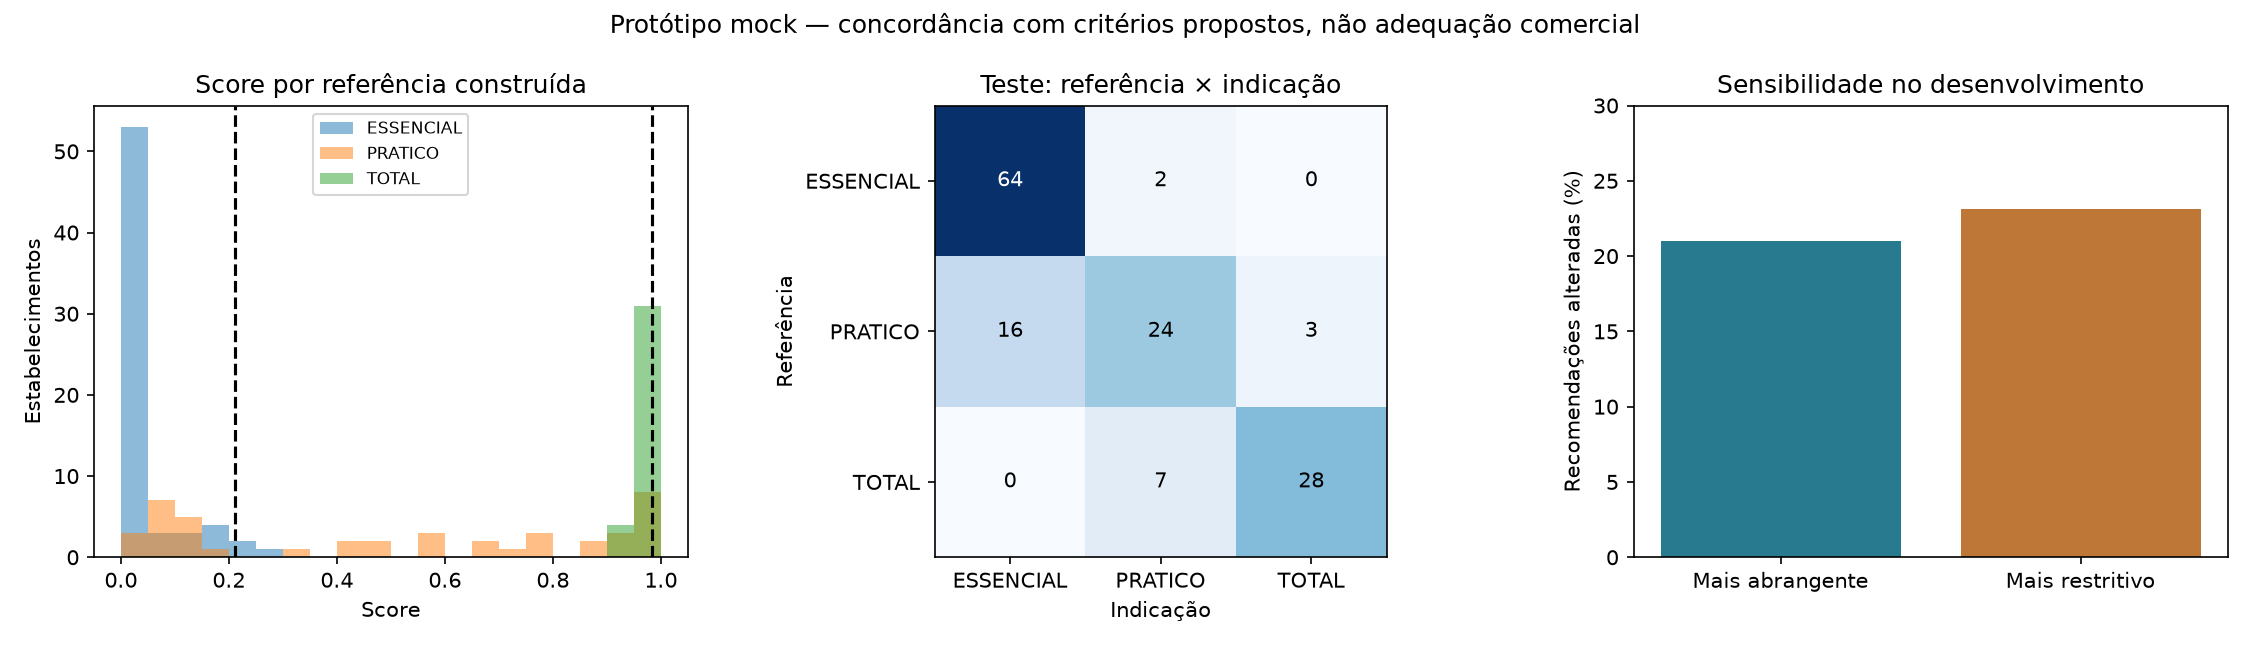

,empresa_id,imovel_id,referencia_criterios,plano_indicado,score,p_ESSENCIAL,p_PRATICO,p_TOTAL,acertou_referencia
0,CASO_00004,IMO_CASO_00004_01,ESSENCIAL,ESSENCIAL,0.008504,0.968878,0.030986,0.000136,True
1,CASO_00026,IMO_CASO_00026_01,ESSENCIAL,PRATICO,0.213372,0.496056,0.499656,0.004288,False
2,CASO_00003,IMO_CASO_00003_01,PRATICO,PRATICO,0.957622,0.011678,0.724299,0.264023,True
3,CASO_00007,IMO_CASO_00007_01,PRATICO,ESSENCIAL,0.118742,0.664610,0.333256,0.002135,False
4,CASO_00001,IMO_CASO_00001_01,TOTAL,TOTAL,0.997373,0.000703,0.141592,0.857705,True
5,CASO_00020,IMO_CASO_00020_01,TOTAL,PRATICO,0.972237,0.007567,0.635128,0.357305,False


In [3]:
display(Image(filename=str(p/'resultados/diagnosticos.png')))
display(pd.read_csv(p/'resultados/casos_explicados.csv'))

In [4]:
display(json.loads((p/'resultados/formula_parametros.json').read_text()))
display(json.loads((p/'resultados/testes_execucao.json').read_text()))
display(json.loads((p/'resultados/perfis_rag_teste.jsonl').read_text().splitlines()[0]))

{'variaveis_numericas': ['funcionarios_estimados_empresa',
  'estoque_medio_estimado',
  'valor_bens_ponderado_estabelecimento'],
 'medianas': [6.0, 25700.0, 131575.0],
 'medias_log1p': [2.090135772782966, 10.102767825413773, 11.774504398967514],
 'desvios_log1p': [0.9046646004797493, 1.7594636346908485, 1.3528137825976125],
 'pesos': [2.9169895933151757, 1.3951985931875512, 1.0123019913128937],
 'limiares_z': [-1.3204957352224693, 4.142976555466792],
 'limiares_score': [0.21073582787904, 0.9843725670088532],
 'formula': 'x_j=(log(1+valor_j)-media_log_j)/desvio_log_j; z=sum(beta_j*x_j); score=1/(1+exp(-z))'}

{'gradiente_analitico': True,
 'probabilidades_somam_um': True,
 'probabilidades_validas': True,
 'score_no_intervalo': True,
 'cortes_ordenados': True,
 'faixas_reproduzem_mediana': True,
 'contribuicoes_reproduzem_score': True,
 'empresas_separadas': True,
 'modelo_nao_alterado_apos_teste': True,
 'exportacao_completa_rag': True,
 'tres_classes_teste': True}

{'versao': 'ordinal_mock_v1',
 'empresa_id': 'CASO_00001',
 'imovel_id': 'IMO_CASO_00001_01',
 'status': 'EXPERIMENTAL_BASE_MOCK',
 'score': 0.9973731372612386,
 'plano_sugerido': 'TOTAL',
 'cortes': [0.21073582787904, 0.9843725670088532],
 'probabilidades_referencia': {'ESSENCIAL': 0.0007027330864187031,
  'PRATICO': 0.1415922308746804,
  'TOTAL': 0.8577050360389009},
 'contribuicoes': [{'variavel': 'num__funcionarios_estimados_empresa',
   'contribuicao_z': 4.227371190679472},
  {'variavel': 'num__valor_bens_ponderado_estabelecimento',
   'contribuicao_z': 1.1602105332428516},
  {'variavel': 'num__estoque_medio_estimado',
   'contribuicao_z': 0.5517529769107072}],
 'elegibilidade': 'NAO_AVALIADA',
 'perguntas': ['Quantos empregados trabalham neste estabelecimento?',
  'Quais bens e estoques estão efetivamente neste endereço?',
  'Há necessidade de cobertura de vidros e exposição a vendaval?'],
 'fontes': ['catalogo_coberturas_fixas_planos.csv',
  'criterios_congelados.json'],
 'limit